# Experiment 6: K-Nearest Neighbors (KNN) Classification

**Dataset:** Breast Cancer Wisconsin Diagnostic dataset (569 observations, 30 numerical features). Built into scikit-learn; no manual Kaggle download is required.

## Aim
Implement KNN to classify observations as malignant or benign and evaluate the classifier.

## Note
This dataset is for educational demonstration only, not for medical diagnosis.

Dataset shape: (569, 31)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  wo

C:\Users\Pragadheesh Pandian\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Pragadheesh Pandian\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, execut


--- KNN Evaluation (k=5) ---
Accuracy: 0.9561
ROC-AUC: 0.9788

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



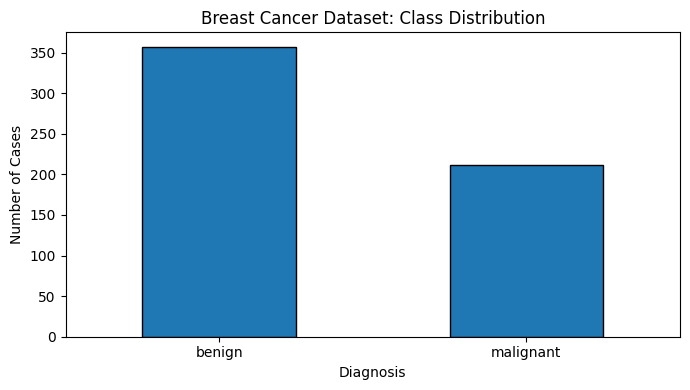

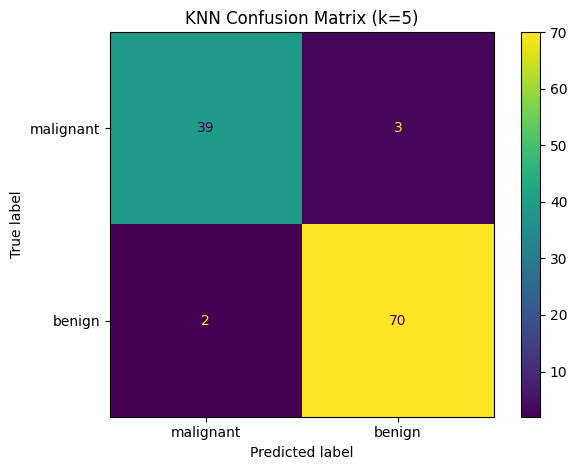

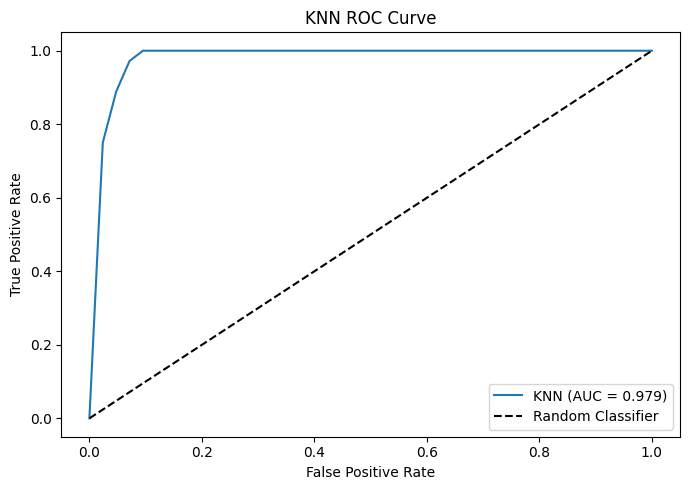

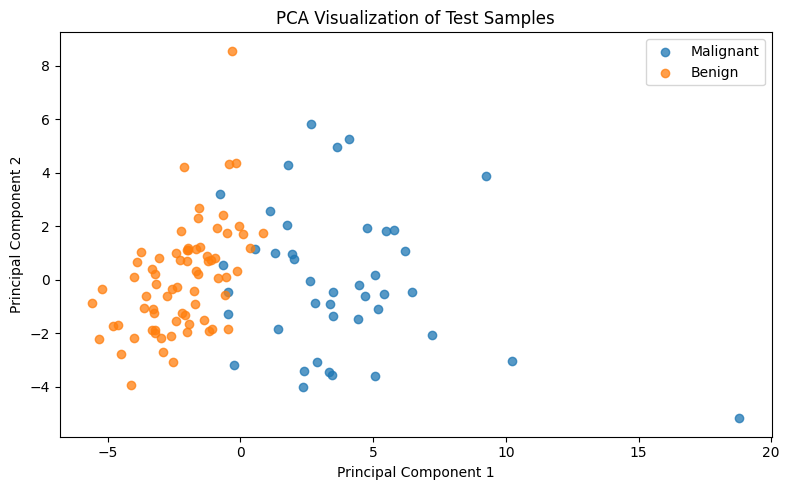


Example Prediction:
Predicted Diagnosis: malignant
Probability of Malignant: 1.0
Probability of Benign: 0.0


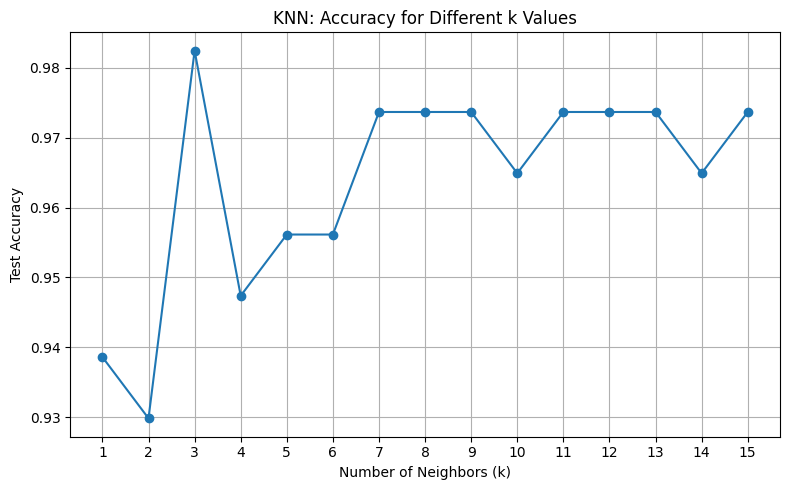

In [1]:
# Experiment 6: K-Nearest Neighbors (KNN) Classification
# Dataset: Breast Cancer Wisconsin Diagnostic dataset (569 observations, 30 features)
# Source: Built into scikit-learn; no manual Kaggle download is required.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)
from sklearn.decomposition import PCA

# Step 1: Load dataset
dataset = load_breast_cancer(as_frame=True)
df = dataset.frame

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nClass distribution:")
print(df["target"].map({0: "malignant", 1: "benign"}).value_counts())

# Step 2: Separate input features and target
X = df[dataset.feature_names]
y = df["target"]  # 0 = malignant, 1 = benign

# Step 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

# Step 4: Build a KNN pipeline
# Scaling is important because KNN uses distances between observations.
k = 5
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=k, metric="minkowski", p=2)
)

# Step 5: Train the model
model.fit(X_train, y_train)

# Step 6: Predict and evaluate
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"\n--- KNN Evaluation (k={k}) ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=dataset.target_names, zero_division=0
))

# Step 7: Plot class distribution
class_counts = df["target"].map({0: "malignant", 1: "benign"}).value_counts()
plt.figure(figsize=(7, 4))
class_counts.plot(kind="bar", edgecolor="black")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.title("Breast Cancer Dataset: Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 8: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=dataset.target_names
).plot(values_format="d")
plt.title(f"KNN Confusion Matrix (k={k})")
plt.tight_layout()
plt.show()

# Step 9: ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

# Step 10: PCA visualization of test samples
# PCA is for visualization only; KNN is trained on all original features.
scaler = model.named_steps["standardscaler"]
X_test_scaled = scaler.transform(X_test)
pca = PCA(n_components=2, random_state=42)
X_test_2d = pca.fit_transform(X_test_scaled)

plt.figure(figsize=(8, 5))
for label, name in [(0, "Malignant"), (1, "Benign")]:
    mask = y_test.to_numpy() == label
    plt.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
                label=name, alpha=0.75)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Test Samples")
plt.legend()
plt.tight_layout()
plt.show()

# Step 11: Predict one sample
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]

print("\nExample Prediction:")
print("Predicted Diagnosis:", dataset.target_names[prediction])
print("Probability of Malignant:", round(probabilities[0], 4))
print("Probability of Benign:", round(probabilities[1], 4))

# Step 12: Compare accuracy for different k values
k_values = range(1, 16)
accuracies = []

for current_k in k_values:
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=current_k)
    )
    knn.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, knn.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), accuracies, marker="o")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test Accuracy")
plt.title("KNN: Accuracy for Different k Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()
